# Regression on Runge's function

Reproduces all figures and tables for the regression problem. The experiments are in `runge_experiments.py`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [1]:
import os, tempfile
import numpy as np
from IPython.display import Image, display

os.environ["PREVIEW_DIR"] = tempfile.mkdtemp()   # the figure code also writes a PNG copy here, shown below
import figures
from plot_style import load_results, set_style

set_style()
RERUN = False    # True runs the experiment again; False draws the figure from the saved numbers in ../results/

def show(name):
    figures.FIGURES[name]()
    display(Image(os.path.join(os.environ["PREVIEW_DIR"], name + ".png"), width=850))


## Polynomial benchmark

The models selected in the earlier study, on the same ten folds (`runge_polynomials.json`).

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [2]:
import runge_experiments as rx
if RERUN:
    rx.polynomial_benchmark()
for k, v in load_results('runge_polynomials').items():
    print(k, 'degree', v['degree'], 'CV MSE %.4f +- %.4f, training MSE %.4f' % (v['cv_mse'], v['cv_se'], v['train_mse']))

OLS degree 12 CV MSE 0.0173 +- 0.0014, training MSE 0.0134
Ridge degree 12 CV MSE 0.0173 +- 0.0014, training MSE 0.0134
Lasso degree 15 CV MSE 0.0192 +- 0.0024, training MSE 0.0158


## Learning rates and optimizers

Figure `runge_learning_rate`, results in `runge_learning_rate.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

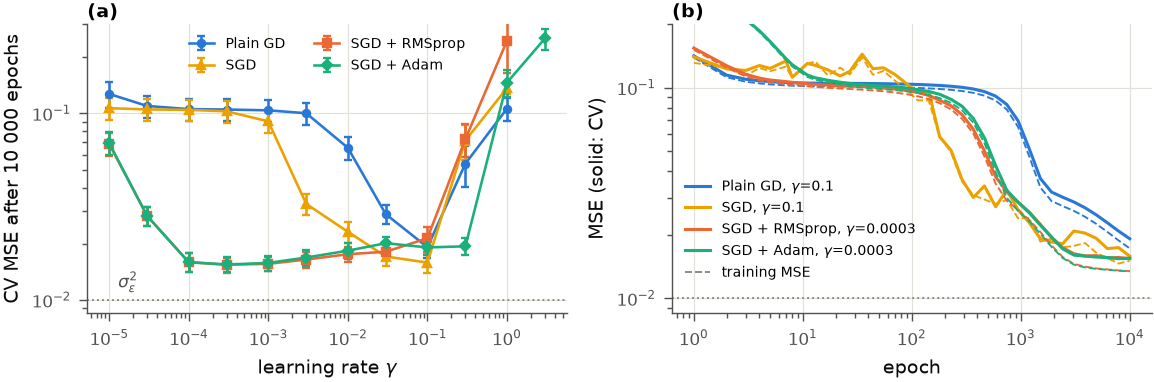

In [3]:
if RERUN:
    rx.learning_rate_scan()
show('runge_learning_rate')

## Batch size and learning rate

Figure `runge_batch`, results in `runge_batch.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

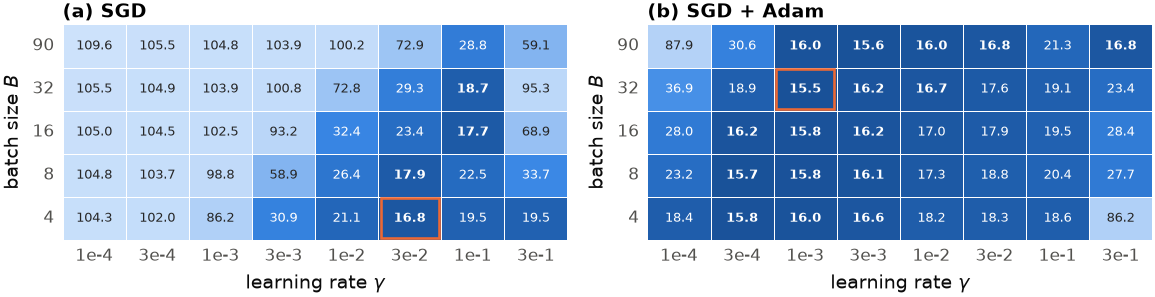

In [4]:
if RERUN:
    rx.batch_scan()
show('runge_batch')

## The architectures of the comparison with OLS

Results in `runge_architectures.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [5]:
if RERUN:
    rx.required_architectures()
for u in load_results('runge_architectures')['runs']:
    s = u['settings']
    print(s['hidden'], 'gamma', s['gamma'], 'best CV MSE %.4f +- %.4f at epoch %d' % (u['best_val'], u['best_val_se'], u['best_epoch']))

[50] gamma 0.0003 best CV MSE 0.0154 +- 0.0015 at epoch 7897
[50] gamma 0.001 best CV MSE 0.0155 +- 0.0016 at epoch 3070
[50] gamma 0.003 best CV MSE 0.0153 +- 0.0015 at epoch 943
[50] gamma 0.01 best CV MSE 0.0159 +- 0.0016 at epoch 1914
[50] gamma 0.03 best CV MSE 0.0167 +- 0.0021 at epoch 55
[100] gamma 0.0003 best CV MSE 0.0154 +- 0.0015 at epoch 7897
[100] gamma 0.001 best CV MSE 0.0155 +- 0.0014 at epoch 3888
[100] gamma 0.003 best CV MSE 0.0160 +- 0.0014 at epoch 2424
[100] gamma 0.01 best CV MSE 0.0164 +- 0.0017 at epoch 3888
[100] gamma 0.03 best CV MSE 0.0173 +- 0.0019 at epoch 1914
[50, 50] gamma 0.0003 best CV MSE 0.0151 +- 0.0016 at epoch 1194
[50, 50] gamma 0.001 best CV MSE 0.0152 +- 0.0017 at epoch 464
[50, 50] gamma 0.003 best CV MSE 0.0150 +- 0.0016 at epoch 229
[50, 50] gamma 0.01 best CV MSE 0.0153 +- 0.0015 at epoch 289
[50, 50] gamma 0.03 best CV MSE 0.0156 +- 0.0017 at epoch 35
[100, 100] gamma 0.0003 best CV MSE 0.0149 +- 0.0015 at epoch 744
[100, 100] gamma 0.0

## Activation functions, depth and width

Figure `runge_activation_maps`, results in `runge_activation_maps.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

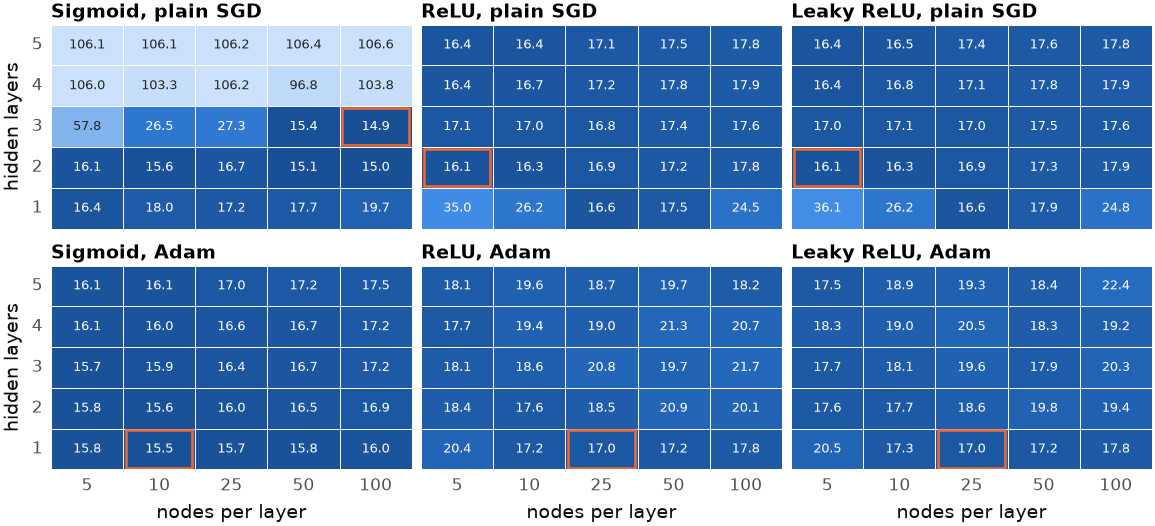

In [6]:
if RERUN:
    rx.activation_maps()
show('runge_activation_maps')

## Vanishing gradients

Figure `runge_gradient_flow`, results in `runge_gradient_flow.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

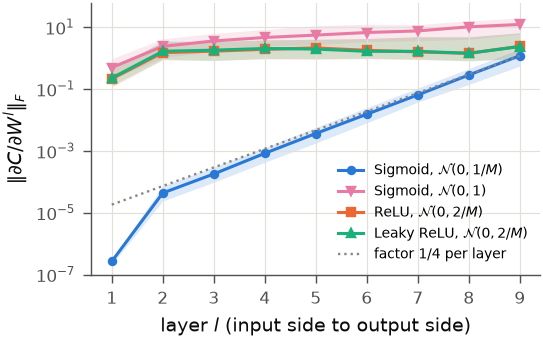

In [7]:
if RERUN:
    rx.gradient_flow()
show('runge_gradient_flow')

## Overfitting and early stopping

Figure `runge_overfitting`, results in `runge_overfitting.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

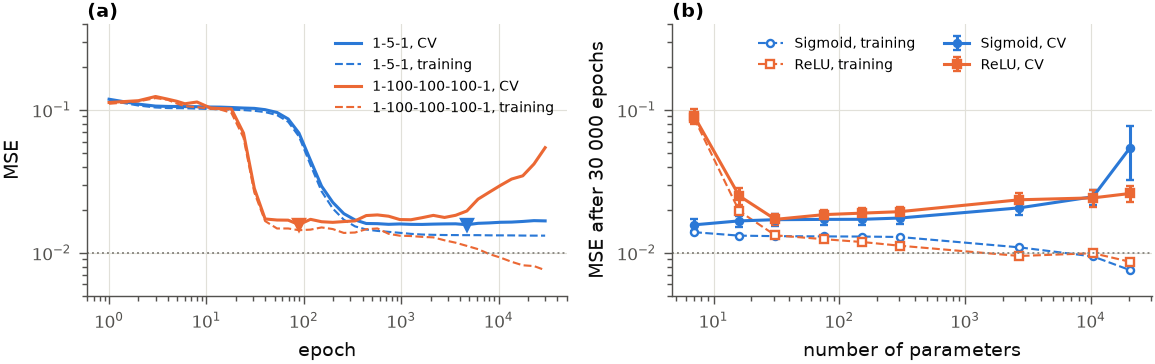

In [8]:
if RERUN:
    rx.overfitting()
show('runge_overfitting')

## Penalties

Figures `runge_penalties` and `runge_sparsity`, results in `runge_penalties.json`, `runge_bias_penalty.json` and `runge_sparsity.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

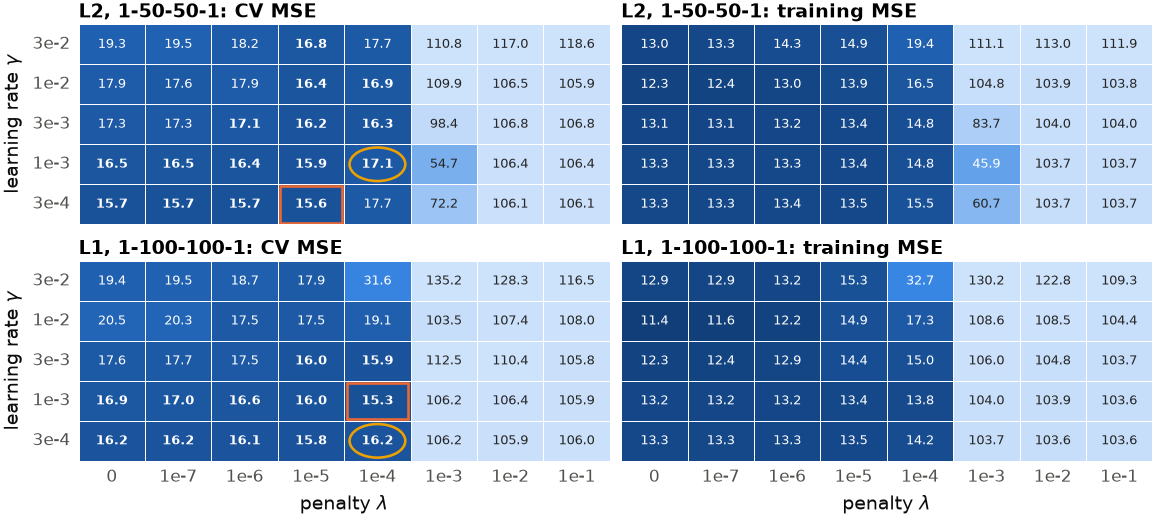

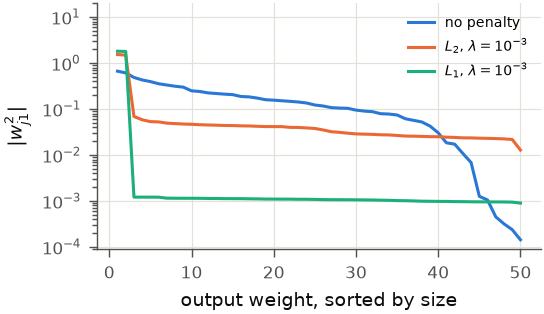

{'l2': {'hidden': [50, 50], 'gamma': 0.001, 'lam': 0.0001, 'with_biases': 0.017110146936976232, 'weights_only': 0.017133509534528572, 'se': 0.002082764709523737}, 'l1': {'hidden': [100, 100], 'gamma': 0.0003, 'lam': 0.0001, 'with_biases': 0.01619440785067172, 'weights_only': 0.016274226065696222, 'se': 0.0020099994514104695}}


In [9]:
if RERUN:
    rx.penalty_scan(); rx.bias_penalty_check(); rx.sparsity()
show('runge_penalties')
show('runge_sparsity')
print(load_results('runge_bias_penalty'))

## Approximation without noise, and many data sets

Figure `runge_approximation`, results in `runge_approximation.json` and `runge_sample_size.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

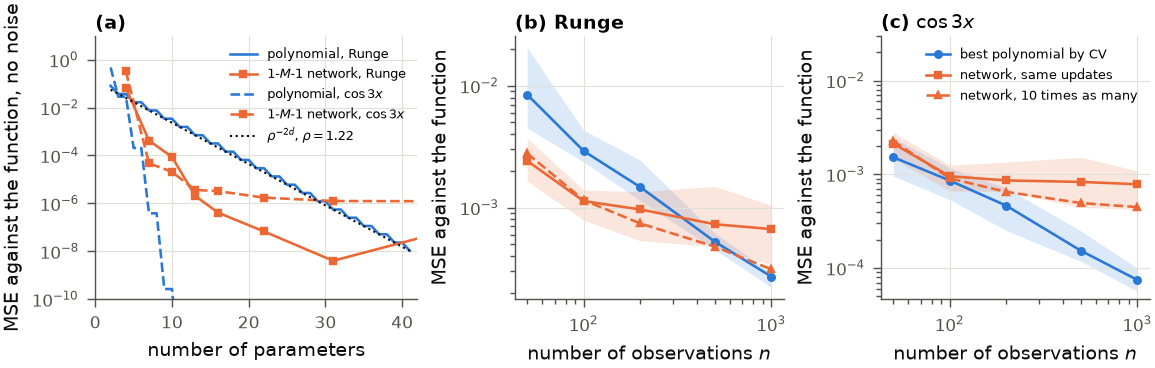

In [10]:
if RERUN:
    rx.approximation_power(); rx.sample_size_study()
show('runge_approximation')

## Final test on the independent observations

Figures `runge_fits` and `runge_features`, results in `runge_final.json` and `runge_features.json`. `final_models` is the only function that reads the 2000 independent observations, and it is run after all choices are made.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

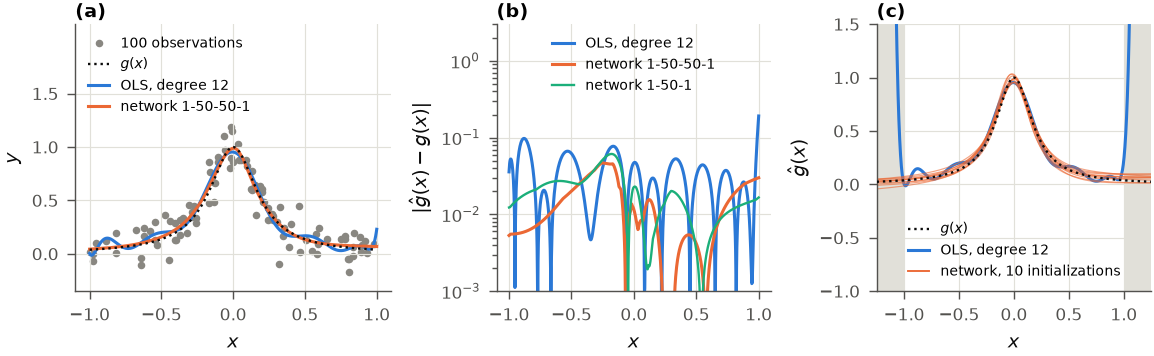

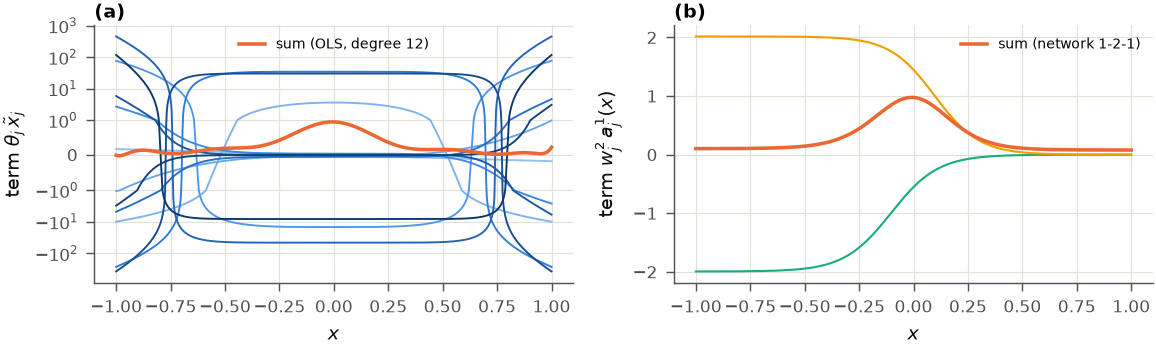

OLS test MSE 0.0113, MSE against f 0.00162
Ridge test MSE 0.0113, MSE against f 0.00162
Lasso test MSE 0.0132, MSE against f 0.00343
50 sigmoid test MSE 0.0107 +- 0.0005, MSE against f 0.00085 +- 0.00057
100 sigmoid test MSE 0.0105 +- 0.0002, MSE against f 0.00058 +- 0.00024
50-50 sigmoid test MSE 0.0111 +- 0.0005, MSE against f 0.00112 +- 0.00056
100-100 sigmoid test MSE 0.0109 +- 0.0009, MSE against f 0.00106 +- 0.00102
2 sigmoid test MSE 0.0112 +- 0.0004, MSE against f 0.00134 +- 0.00046
5 sigmoid test MSE 0.0105 +- 0.0002, MSE against f 0.00060 +- 0.00022
l2 one-se test MSE 0.0115 +- 0.0003, MSE against f 0.00171 +- 0.00035
l1 one-se test MSE 0.0111 +- 0.0004, MSE against f 0.00131 +- 0.00039
best relu test MSE 0.0111 +- 0.0004, MSE against f 0.00118 +- 0.00044
best leaky_relu test MSE 0.0111 +- 0.0004, MSE against f 0.00118 +- 0.00042


In [11]:
if RERUN:
    rx.final_models(); rx.features()
show('runge_fits')
show('runge_features')
final = load_results('runge_final')
for k, v in final['polynomial'].items():
    print(k, 'test MSE %.4f, MSE against f %.5f' % (v['test_mse'], v['true_mse']))
for k, v in final['network'].items():
    print(k, 'test MSE %.4f +- %.4f, MSE against f %.5f +- %.5f' % (v['test_mse'], v['test_std'], v['true_mse'], v['true_std']))

## Measurements behind the explanations

How far training moves the parameters from their initial values, next to the CV error, for the sigmoid networks of the overfitting study; and how much plain SGD and Adam change each layer of a sigmoid network with five hidden layers (`runge_mechanisms.json`). Only the 100 observations are used.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [12]:
if RERUN:
    rx.mechanisms()
m = load_results('runge_mechanisms')
for r in m['distance']:
    print(r['settings']['hidden'], r['n_parameters'], 'parameters: best epoch', r['best_epoch'],
          'CV MSE %.4f, distance moved %.2f (after 30 000 epochs %.2f)' % (r['best_val'], r['best_distance'], r['distance'][-1]))
for c in m['layer_changes']:
    print(c['optimizer'], 'gamma', c['gamma'], 'relative change of each layer after', c['epochs'][-1], 'epochs:',
          np.round(c['median'][-1], 4), 'training MSE %.4f' % np.median(c['train_mse']))

[2] 7 parameters: best epoch 4716 CV MSE 0.0156, distance moved 6.90 (after 30 000 epochs 6.83)
[5] 16 parameters: best epoch 4716 CV MSE 0.0157, distance moved 9.19 (after 30 000 epochs 11.34)
[10] 31 parameters: best epoch 741 CV MSE 0.0154, distance moved 9.76 (after 30 000 epochs 24.83)
[25] 76 parameters: best epoch 741 CV MSE 0.0157, distance moved 8.86 (after 30 000 epochs 42.20)
[50] 151 parameters: best epoch 569 CV MSE 0.0151, distance moved 8.91 (after 30 000 epochs 70.73)
[100] 301 parameters: best epoch 2779 CV MSE 0.0159, distance moved 19.23 (after 30 000 epochs 111.28)
[50, 50] 2701 parameters: best epoch 335 CV MSE 0.0151, distance moved 9.39 (after 30 000 epochs 74.24)
[100, 100] 10401 parameters: best epoch 335 CV MSE 0.0154, distance moved 9.90 (after 30 000 epochs 154.30)
[100, 100, 100] 20501 parameters: best epoch 89 CV MSE 0.0158, distance moved 9.75 (after 30 000 epochs 196.54)
adam gamma 0.001 relative change of each layer after 3000 epochs: [0.8373 2.0899 1.3